In [1]:
# ============================================================
# Cell 1: Production Dependencies (requirements.txt)
# ============================================================
!pip -q install torch torchvision open-clip-torch insightface onnxruntime albumentations opencv-python-headless Pillow numpy captum


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 762.2/762.2 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 39.5 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ============================================================
# Cell 2: Core Model Architecture (model.py)
# ============================================================
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import open_clip

@dataclass
class ModelConfig:
    hidden1: int = 512
    hidden2: int = 256
    feature_dropout: float = 0.1
    fc_dropout: float = 0.4

class FrozenFaceBackbone(nn.Module):
    embedding_dim = 512
    def __init__(self):
        super().__init__()
        self.model = models.resnet50(weights=None)
        self.model.fc = nn.Linear(self.model.fc.in_features, self.embedding_dim)
        self.model.eval()
        for p in self.model.parameters(): p.requires_grad_(False)

        self.register_buffer("mean", torch.tensor([0.5, 0.5, 0.5]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.5, 0.5, 0.5]).view(1, 3, 1, 1))

    def forward(self, x01):
        x = (x01 - self.mean) / self.std
        emb = self.model(x)
        return F.normalize(emb, dim=1)


class FrozenCLIPBackbone(nn.Module):
    embedding_dim = 768
    def __init__(self):
        super().__init__()
        # Load FULL CLIP model so we can use both Vision and Text encoders
        self.clip_model, _, _ = open_clip.create_model_and_transforms('ViT-L-14', pretrained='openai')
        self.tokenizer = open_clip.get_tokenizer('ViT-L-14')

        self.clip_model.eval()
        for p in self.clip_model.parameters(): p.requires_grad_(False)

        clip_mean = [0.48145466, 0.4578275, 0.40821073]
        clip_std = [0.26862954, 0.26130258, 0.27577711]
        self.register_buffer("mean", torch.tensor(clip_mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(clip_std).view(1, 3, 1, 1))

    def forward(self, x01):
        x = (x01 - self.mean) / self.std
        feat = self.clip_model.visual(x)
        return F.normalize(feat.float(), dim=1)

    @torch.no_grad()
    def encode_concepts(self, concepts: list[str], device: str) -> torch.Tensor:
        """Encodes human-readable text into 768-dim semantic vectors."""
        tokens = self.tokenizer(concepts).to(device)
        text_features = self.clip_model.encode_text(tokens)
        return F.normalize(text_features.float(), dim=1)


class FusionHead(nn.Module):
    def __init__(self, face_dim: int, clip_dim: int, hidden1: int, hidden2: int, feat_drop: float, fc_drop: float):
        super().__init__()
        self.input_norm = nn.LayerNorm(face_dim + clip_dim)
        self.feature_dropout = nn.Dropout(feat_drop)
        self.net = nn.Sequential(
            nn.Linear(face_dim + clip_dim, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.GELU(),
            nn.Dropout(fc_drop),
            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.GELU(),
            nn.Dropout(fc_drop),
            nn.Linear(hidden2, 1),
        )

    def forward(self, face_emb, clip_emb):
        x = torch.cat([face_emb, clip_emb], dim=1)
        return self.net(self.feature_dropout(self.input_norm(x))).squeeze(1)


class FusionModel(nn.Module):
    def __init__(self, cfg: ModelConfig = ModelConfig()):
        super().__init__()
        self.face_backbone = FrozenFaceBackbone()
        self.clip_backbone = FrozenCLIPBackbone()
        self.head = FusionHead(
            self.face_backbone.embedding_dim,
            self.clip_backbone.embedding_dim,
            cfg.hidden1, cfg.hidden2, cfg.feature_dropout, cfg.fc_dropout
        )

    def forward(self, x_384):
        clip_input = F.interpolate(x_384, size=(224, 224), mode='bicubic', antialias=True)
        crop_size = int(x_384.shape[-1] * 0.8)
        start = (x_384.shape[-1] - crop_size) // 2
        face_crop = x_384[:, :, start:start + crop_size, start:start + crop_size]
        face_input = F.interpolate(face_crop, size=(112, 112), mode='bicubic', antialias=True)
        return self.head(self.face_backbone(face_input), self.clip_backbone(clip_input))

    def get_clip_embedding(self, x_384):
        """Helper to extract the 768-dim vector for concept matching."""
        clip_input = F.interpolate(x_384, size=(224, 224), mode='bicubic', antialias=True)
        return self.clip_backbone(clip_input)


In [4]:
# ============================================================
# Cell 3: Preprocessing & Cropping Pipeline (preprocessing.py)
# ============================================================
import numpy as np
import cv2
from PIL import Image
import torch
import albumentations as A
from albumentations.pytorch import ToTensorV2
from insightface.app import FaceAnalysis

class ProductionFacePreprocessor:
    def __init__(self, device: str = "cpu", offline_margin: float = 1.4, master_size: int = 384):
        self.device = device
        self.offline_margin = offline_margin
        self.master_size = master_size
        self.fallback_center_crop_frac = 0.8

        self.detector = FaceAnalysis(
            name="buffalo_l",
            allowed_modules=["detection"],
            providers=["CUDAExecutionProvider"] if device == "cuda" else ["CPUExecutionProvider"],
        )
        self.detector.prepare(ctx_id=0 if device == "cuda" else -1, det_size=(640, 640))
        self.transform = A.Compose([ToTensorV2()])

    def _expand_and_square_box(self, box, margin):
        x1, y1, x2, y2 = box
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        side = max(x2 - x1, y2 - y1) * margin
        half = side / 2
        return cx - half, cy - half, cx + half, cy + half

    def _crop_with_reflect_pad(self, image_pil, box):
        img_w, img_h = image_pil.size
        x1, y1, x2, y2 = [int(round(v)) for v in box]
        pad_left = max(0, -x1)
        pad_top = max(0, -y1)
        pad_right = max(0, x2 - img_w)
        pad_bottom = max(0, y2 - img_h)

        if any([pad_left, pad_top, pad_right, pad_bottom]):
            arr = np.array(image_pil)
            arr = np.pad(arr, ((pad_top, pad_bottom), (pad_left, pad_right), (0, 0)), mode="reflect")
            image_pil = Image.fromarray(arr)
            x1, y1, x2, y2 = x1 + pad_left, y1 + pad_top, x2 + pad_left, y2 + pad_top

        return image_pil.crop((x1, y1, x2, y2))

    def process_pil_image(self, image_pil: Image.Image) -> tuple[torch.Tensor, Image.Image]:
        """Returns both the tensor and the cropped PIL image (needed for heatmap overlay)."""
        image_pil = image_pil.convert("RGB")
        bgr = np.array(image_pil)[:, :, ::-1]
        faces = self.detector.get(bgr)

        if not faces:
            img_w, img_h = image_pil.size
            side = min(img_w, img_h) * self.fallback_center_crop_frac
            cx, cy = img_w / 2, img_h / 2
            inner_box = (cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)
        else:
            best = max(faces, key=lambda f: f.det_score)
            x1, y1, x2, y2 = best.bbox
            inner_box = (float(x1), float(y1), float(x2), float(y2))

        box = self._expand_and_square_box(inner_box, self.offline_margin)
        cropped = self._crop_with_reflect_pad(image_pil, box)
        resized_crop = cropped.resize((self.master_size, self.master_size), Image.Resampling.LANCZOS)

        img_array = np.array(resized_crop)
        tensor = self.transform(image=img_array)["image"].float() / 255.0
        return tensor.unsqueeze(0), resized_crop


In [5]:
# ============================================================
# Cell 4: Production Explainable API Handler (inference_engine.py)
# ============================================================
import io
import base64
import torch
import torch.nn as nn
import numpy as np
import cv2
from PIL import Image
from typing import Dict, Any, Union
from captum.attr import Saliency
# from captum.attr import LayerGradCam, LayerAttribution


class CaptumWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        return self.model(x).unsqueeze(1)

class ExplainableAIDetectionService:
    def __init__(self, checkpoint_path: str, optimal_temperature: float = 0.7712, device: str = None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.optimal_temp = optimal_temperature

        print(f"[Init] Starting Explainable AI Service on {self.device}...")
        self.preprocessor = ProductionFacePreprocessor(device=self.device)
        self.model = FusionModel(ModelConfig()).to(self.device)

        checkpoint = torch.load(checkpoint_path, map_location=self.device)

        # strict=False allows us to skip the missing CLIP text encoder keys
        if "model_state_dict" in checkpoint:
            self.model.load_state_dict(checkpoint["model_state_dict"], strict=False)
        else:
            self.model.load_state_dict(checkpoint, strict=False)

        # self.model.eval()
        # # Hook into the deepest convolutional layer of the ResNet face backbone
        # target_layer = self.model.face_backbone.model.layer4
        # self.saliency_engine = LayerGradCam(CaptumWrapper(self.model), target_layer)
        # self._init_concepts()

        self.model.eval()
        self.saliency_engine = Saliency(CaptumWrapper(self.model))
        self._init_concepts()


        print("[Init] Service successfully initialized and ready!")

    def _init_concepts(self):
        self.ai_concepts = [
            "unnatural smooth skin texture",
            "asymmetric facial features or pupils",
            "synthetic lighting and artificial glow",
            "blurry edges and digital artifacts"
        ]
        self.real_concepts = [
            "natural skin pores and fine wrinkles",
            "authentic camera lighting and shadow depth",
            "realistic hair strands",
            "natural photo grain"
        ]
        self.ai_embeds = self.model.clip_backbone.encode_concepts(self.ai_concepts, self.device)
        self.real_embeds = self.model.clip_backbone.encode_concepts(self.real_concepts, self.device)

    # def _generate_heatmap_base64(self, input_tensor: torch.Tensor, face_crop_pil: Image.Image) -> str:
    #     input_tensor.requires_grad_()
    #     grads = self.saliency_engine.attribute(input_tensor, target=0)

    #     # 1. Get raw pixel gradients at full 384x384 resolution
    #     grads = grads.squeeze().cpu().detach().numpy()
    #     grads = np.max(np.abs(grads), axis=0)

    #     # 2. HEAVY Gaussian Blur (Melts the static into smooth, glowing blobs)
    #     grads = cv2.GaussianBlur(grads, (75, 75), 0)

    #     # 3. Percentile Clipping (Drop the extreme outliers)
    #     p99 = np.percentile(grads, 99.5)
    #     grads = np.clip(grads, 0, p99)

    #     # 4. Standard Normalize (0 to 1)
    #     grads = (grads - np.min(grads)) / (np.max(grads) - np.min(grads) + 1e-8)

    #     # 5. Clean up the noise (Zero out anything below 25% intensity)
    #     grads[grads < 0.25] = 0

    #     # 6. Apply Colors (JET maps low values to blue, high to red)
    #     heatmap = np.uint8(255 * grads)
    #     heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    #     # 7. Premium Alpha Blending!
    #     # Only color the active spots, leave the rest of the image totally clear.
    #     orig_cv = cv2.cvtColor(np.array(face_crop_pil), cv2.COLOR_RGB2BGR)

    #     # Create transparency based on how strong the gradient is
    #     alpha = np.expand_dims(grads, axis=-1)
    #     alpha = np.clip(alpha * 1.5, 0, 1) # Boost the opacity of the glowing spots

    #     superimposed = (orig_cv * (1 - alpha) + heatmap_color * alpha).astype(np.uint8)

    #     _, buffer = cv2.imencode('.png', superimposed)
    #     return "data:image/png;base64," + base64.b64encode(buffer).decode('utf-8')




    def _generate_heatmap_base64(self, input_tensor: torch.Tensor, face_crop_pil: Image.Image) -> str:
        input_tensor.requires_grad_()
        grads = self.saliency_engine.attribute(input_tensor, target=0)

        # 1. Get raw pixel gradients
        grads = grads.squeeze().cpu().detach().numpy()
        grads = np.max(np.abs(grads), axis=0)

        # 2. Heavy Gaussian Blur
        grads = cv2.GaussianBlur(grads, (75, 75), 0)

        # 3. Widen the hotspots
        p90 = np.percentile(grads, 90.0)
        grads = np.clip(grads, 0, p90)

        # 4. Standard Normalize
        grads = (grads - np.min(grads)) / (np.max(grads) - np.min(grads) + 1e-8)

        # 5. Reveal more areas (Noise floor)
        grads[grads < 0.05] = 0

        # 6. Apply Colors
        heatmap = np.uint8(255 * grads)
        heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

        # 7. Alpha Blending (TRANSLUCENT FIX)
        orig_cv = cv2.cvtColor(np.array(face_crop_pil), cv2.COLOR_RGB2BGR)
        alpha = np.expand_dims(grads, axis=-1)

        # Multiply by 1.5 to keep colors vibrant, but HARD CAP at 0.55 (55% opacity)
        # This guarantees at least 45% of the original photo always shines through!
        alpha = np.clip(alpha * 1.5, 0, 0.55)

        superimposed = (orig_cv * (1 - alpha) + heatmap_color * alpha).astype(np.uint8)

        _, buffer = cv2.imencode('.png', superimposed)
        return "data:image/png;base64," + base64.b64encode(buffer).decode('utf-8')





    @torch.no_grad()
    def _get_concept_explanations(self, clip_embed: torch.Tensor, is_ai: bool) -> list:
        concepts = self.ai_concepts if is_ai else self.real_concepts
        text_embeds = self.ai_embeds if is_ai else self.real_embeds

        similarities = (clip_embed @ text_embeds.T).squeeze(0)
        scores = torch.softmax(similarities * 10, dim=-1).cpu().numpy()

        results = []
        for i, concept in enumerate(concepts):
            results.append({
                "concept": concept,
                "relevance_pct": round(float(scores[i]) * 100, 1)
            })

        results.sort(key=lambda x: x["relevance_pct"], reverse=True)
        return results[:3]

    def predict(self, image_input: Union[str, bytes, Image.Image]) -> Dict[str, Any]:
        if isinstance(image_input, str): image_pil = Image.open(image_input)
        elif isinstance(image_input, bytes): image_pil = Image.open(io.BytesIO(image_input))
        else: image_pil = image_input

        tensor, face_crop_pil = self.preprocessor.process_pil_image(image_pil)
        tensor = tensor.to(self.device)

        with torch.no_grad():
            logits = self.model(tensor)
            clip_embed = self.model.get_clip_embedding(tensor)
            prob = torch.sigmoid(logits / self.optimal_temp).item()

        is_ai = prob >= 0.5
        confidence = prob if is_ai else (1.0 - prob)

        explanations = self._get_concept_explanations(clip_embed, is_ai)

        with torch.enable_grad():
            heatmap_b64 = self._generate_heatmap_base64(tensor.clone(), face_crop_pil)

        # The missing key is guaranteed to be here now
        return {
            "status": "success",
            "is_ai": is_ai,
            "label": "AI-Generated" if is_ai else "Real Photo",
            "confidence": round(confidence * 100, 2),
            "explanations": explanations,
            "heatmap_base64": heatmap_b64,
            "cropped_image": face_crop_pil
        }


Loading Models & Captum Engine (This takes a few seconds)...
[Init] Starting Explainable AI Service on cpu...
download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:05<00:00, 51886.32KB/s]


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /root/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /root/.insightface/models/buffalo_l/w600k_r50.onnx recognition
set det-size: (640, 640)


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


[Init] Service successfully initialized and ready!

READY: Upload an image to test Explainable AI


Saving IMG_3835.jpeg to IMG_3835.jpeg

Analyzing IMG_3835.jpeg...

 PREDICTION : AI-Generated (93.47%)

TOP SEMANTIC INSIGHTS (CLIP Concept Attribution):
 🔹 Asymmetric Facial Features Or Pupils: 33.5%
 🔹 Unnatural Smooth Skin Texture: 27.6%
 🔹 Synthetic Lighting And Artificial Glow: 21.8%



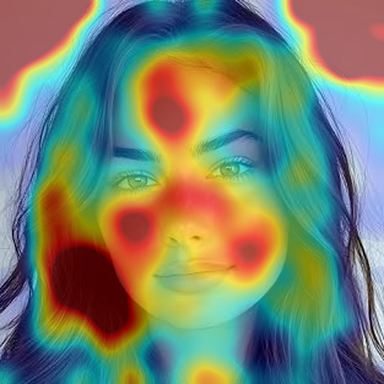

In [6]:
# ============================================================
# Cell 5: Interactive Colab Test for Explainable API
# ============================================================
import os
import base64
from IPython.display import display, HTML
from google.colab import files

# 1. Initialize the service (It only loads the models once)
checkpoint_path = "/content/drive/MyDrive/AI_Image_Detection/checkpoints_final/best_final_model.pt"

if 'explainer_service' not in locals():
    print("Loading Models & Captum Engine (This takes a few seconds)...")
    explainer_service = ExplainableAIDetectionService(checkpoint_path)

# 2. Upload and Analyze Image
print("\n" + "="*50)
print("READY: Upload an image to test Explainable AI")
print("="*50)

uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nAnalyzing {filename}...")

    # 3. Call the API exactly as your backend server will
    result = explainer_service.predict(filename)

    # 4. Beautifully format the JSON response for Colab reading
    print("\n" + "="*50)
    print(f" PREDICTION : {result['label']} ({result['confidence']}%)")
    print("="*50)

    print("\nTOP SEMANTIC INSIGHTS (CLIP Concept Attribution):")
    for exp in result['explanations']:
        print(f" 🔹 {exp['concept'].title()}: {exp['relevance_pct']}%")

    # 5. Render the Base64 string back into a visual image using HTML
    b64_data = result['heatmap_base64'].split(',')[1]
    html_code = f'''
    <div style="margin-top: 15px;">
        <h3 style="font-family: sans-serif;">Spatial Attribution Heatmap (Captum):</h3>
        <img src="data:image/png;base64,{b64_data}" style="max-width: 400px; border: 3px solid {'darkred' if result['is_ai'] else 'darkgreen'}; border-radius: 8px;" />
    </div>
    '''
    display(HTML(html_code))

    # Clean up file so Colab doesn't get cluttered
    os.remove(filename)


Service already loaded in memory. Ready for instant inference!

UPLOAD AN IMAGE


Saving IMG_9609.jpeg to IMG_9609.jpeg



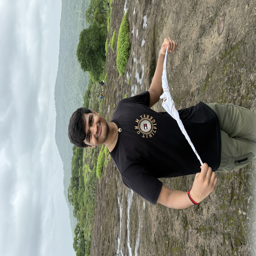
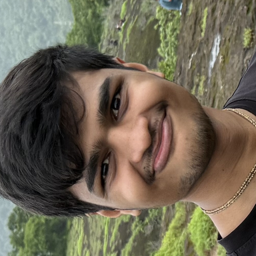
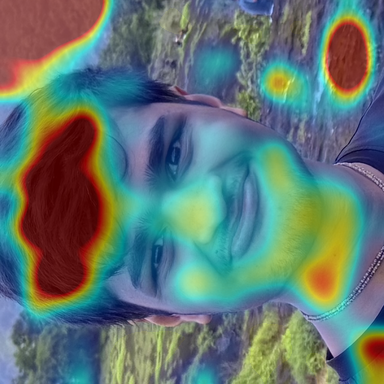

In [11]:
# ============================================================
# FAST INFERENCE LOOP (Run this as many times as you want)
# ============================================================
import os
import io
import base64
from IPython.display import display, HTML
from PIL import Image
from google.colab import files

# Helper to format images for the Colab UI
def pil_to_b64(img, size=(256, 256)):
    buf = io.BytesIO()
    img.copy().resize(size).save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode('utf-8')

# Ensure the service is loaded (this prevents the repeated downloading!)
if 'explainer_service' not in locals():
    print("Initializing service ONE TIME...")
    explainer_service = ExplainableAIDetectionService("/content/drive/MyDrive/AI_Image_Detection/checkpoints_final/best_final_model.pt")
else:
    print("Service already loaded in memory. Ready for instant inference!")

print("\n" + "="*50)
print("UPLOAD AN IMAGE")
print("="*50)

uploaded = files.upload()

for filename in uploaded.keys():
    # 1. Get Prediction
    result = explainer_service.predict(filename)

    # 2. Prepare Images
    orig_img = Image.open(filename).convert("RGB")
    orig_b64 = pil_to_b64(orig_img)
    crop_b64 = pil_to_b64(result['cropped_image'])
    heat_b64 = result['heatmap_base64'].split(',')[1]

    # 3. Format the UI Color and Concepts
    color = "#8b0000" if result['is_ai'] else "#006400"
    concepts_html = "".join([f"<li style='margin-bottom: 4px;'><b>{c['concept'].title()}</b>: {c['relevance_pct']}%</li>" for c in result['explanations']])

    # 4. Generate Side-by-Side HTML Dashboard
    html_code = f'''
    <div style="font-family: sans-serif; max-width: 900px; padding: 20px; border: 2px solid {color}; border-radius: 10px; background-color: #f8f9fa; color: #333;">
        <h2 style="color: {color}; margin-top: 0;">Prediction: {result['label']} ({result['confidence']}%)</h2>

        <div style="margin-bottom: 20px;">
            <h4 style="margin-bottom: 8px;">Top Semantic Insights:</h4>
            <ul style="margin-top: 0;">
                {concepts_html}
            </ul>
        </div>

        <div style="display: flex; gap: 15px; justify-content: space-between; text-align: center;">
            <div style="flex: 1;">
                <h4 style="margin-bottom: 5px;">Original Upload</h4>
                <img src="data:image/png;base64,{orig_b64}" style="width: 100%; max-width: 256px; border-radius: 8px; box-shadow: 0 4px 6px rgba(0,0,0,0.1);" />
            </div>
            <div style="flex: 1;">
                <h4 style="margin-bottom: 5px;">Preprocessed Face</h4>
                <img src="data:image/png;base64,{crop_b64}" style="width: 100%; max-width: 256px; border-radius: 8px; box-shadow: 0 4px 6px rgba(0,0,0,0.1);" />
            </div>
            <div style="flex: 1;">
                <h4 style="margin-bottom: 5px;">Attribution Heatmap</h4>
                <img src="data:image/png;base64,{heat_b64}" style="width: 100%; max-width: 256px; border-radius: 8px; border: 3px solid {color}; box-shadow: 0 4px 6px rgba(0,0,0,0.1);" />
            </div>
        </div>
    </div>
    '''

    display(HTML(html_code))
    os.remove(filename)


In [ ]:
# Initialize ONCE on startup
service = ExplainableAIDetectionService("/content/drive/MyDrive/AI_Image_Detection/checkpoints_final/best_final_model.pt")

# Call on every user request
result = service.predict("path/to/upload.jpg")
print(result)
